In [2]:
from langgraph.constants import START, END
from typing import TypedDict

from langgraph.graph import StateGraph


# 1.定义状态 - 只要继承了TypedDict，当前的类是一个真正的字典，在状态图中流转的就是这个字典
class SimpleState(TypedDict):
    name: str
    greeting: str
# 2.定义节点 - 本质是一个函数
    # 参数必须是流转的状态类对象
    # 返回值是字典，只需要返回需要更新的KEY
# 2.1 生成问候语
def greet_node(state: SimpleState):
    print(f"节点1: {state}")
    greeting_str = f"Hello, {state["name"]}"
    return {"greeting": greeting_str}
# 2.2 把问候语转大写
def upper_node(state: simpleState):
    print(f"节点2: {state}")
    greeting_upper = state["name"].upper()
    return {"greeting": greeting_upper}
# 3.定义边，连接节点，形成图
builder = StateGraph(SimpleState)
# 3.1 添加节点 - 节点名称可以自定义，边连接的时候能对应上即可
builder.add_node("greet_node", greet_node)
builder.add_node("upper_node", upper_node)
# 3.2 添加边 - 两部分组成，起始节点
builder.add_edge(START, "greet_node")
builder.add_edge("greet_node", "upper_node")
builder.add_edge("upper_node", END)
# 3.3 编译 - 形成一个编译过的状态图 - 后面就可以调用这个图了
graph = builder.compile()

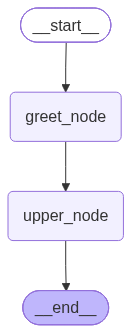

In [4]:
# 4.调用图 - 像调用智能体一样 - 参数和结果受限于流转的数据，必须是字典
from IPython.core.display import Image

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))